# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, levene, ttest_ind

In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [3]:
# explorar datasets
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


---

In [4]:
# explorar datasets
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [5]:
# explorar datasets
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [6]:
# información general de catalog
catalog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [7]:
# explorar datasets
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


In [8]:
# información general de marketing
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


### 1.2. Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas
---

In [9]:
# Convertir a fecha la columna `fecha_hora_pedido` de orders
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'])

In [10]:
# verificacón de información general de orders
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


In [11]:
# revisar variables numéricas (sin negativos o ceros inválidos).
orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25050.000000,25050.000000,25050.000000,2.510000e+04
mean,7.092735,259.305549,4.500798,2.072680e+03
std,296.277003,138.726461,5.223010,9.894995e+04
min,-2.000000,20.030000,0.000000,-4.926500e+02
25%,1.000000,138.377500,0.000000,1.805075e+02
50%,2.000000,258.715000,0.000000,3.417500e+02
75%,2.000000,380.332500,10.000000,5.185800e+02
max,20000.000000,499.960000,15.000000,8.840200e+06


In [12]:
# filtrar y quedarte solo con las filas donde cantidad sea válida (mayor a 0)
orders = orders[orders['cantidad'] > 0]
# revisar variables numéricas (sin negativos o ceros inválidos).
orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25046.000000,25046.000000,25046.000000,2.504600e+04
mean,7.094067,259.304400,4.500719,2.076331e+03
std,296.300643,138.715188,5.223232,9.905653e+04
min,1.000000,20.030000,0.000000,5.240000e+00
25%,1.000000,138.405000,0.000000,1.804025e+02
50%,2.000000,258.715000,0.000000,3.415600e+02
75%,2.000000,380.272500,10.000000,5.184375e+02
max,20000.000000,499.960000,15.000000,8.840200e+06


In [13]:
# 1. Definimos el umbral
umbral = 100

# 2. Contamos las filas que cumplen la condición
# (La condición genera True/False, y .sum() cuenta los True como 1)
total_filas = (orders['cantidad'] > umbral).sum()

print(f"Número de filas por encima de {umbral}: {total_filas}")

Número de filas por encima de 100: 10


In [14]:
# 1. Definimos el umbral
umbral = 10000

# 2. Contamos las filas que cumplen la condición
# (La condición genera True/False, y .sum() cuenta los True como 1)
total_filas = (orders['monto_total'] > umbral).sum()

print(f"Número de filas por encima de {umbral}: {total_filas}")

Número de filas por encima de 10000: 10


In [15]:
# revisar que sean las mismas filas de cantidad (mayor a 100) y  monto_total (mayor a 10000)
revision = orders[(orders['cantidad'] > 100) & (orders['monto_total'] > 10000)]
print(revision)

       id_pedido id_usuario fecha_hora_pedido       pais dispositivo  \
3521  order_3521  user_5812        2025-02-03     Mexico      mobile   
3522  order_3522  user_3575        2025-03-29  Argentina     desktop   
3586  order_3586  user_3380        2025-02-03     Mexico      mobile   
3643  order_3643  user_4440        2025-01-07   Colombia     desktop   
3656  order_3656   user_884        2025-01-01  Argentina      mobile   
3668  order_3668  user_7270        2025-06-24     Mexico      mobile   
3689  order_3689  user_6566        2025-06-16     mexico     desktop   
3722  order_3722  user_4723        2025-05-09  Argentina      mobile   
3726  order_3726  user_2536        2025-02-12   Colombia     desktop   
3748  order_3748  user_7096        2025-02-23     Mexico     desktop   

     fuente_referencia     nombre_producto categoria_producto  cantidad  \
3521       paid_search  Laptop-Gaming-16GB        Electronica   10000.0   
3522            social  Laptop-Gaming-16GB        Electro

In [16]:
# filtrar y quedarte solo con las filas donde cantidad sea válida cantidad (menor a 100) y monto_total(menor a 10000)
orders = orders[~ ((orders['cantidad'] > 100) & (orders['monto_total'] > 10000))]
# revisar variables numéricas (sin negativos o ceros inválidos).
orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25036.000000,25036.000000,25036.000000,25036.000000
mean,1.504953,259.293912,4.502516,385.807512
std,0.499985,138.716939,5.223500,255.750599
min,1.000000,20.030000,0.000000,5.240000
25%,1.000000,138.392500,0.000000,180.330000
50%,2.000000,258.700000,0.000000,341.360000
75%,2.000000,380.297500,10.000000,517.640000
max,2.000000,499.960000,15.000000,999.890000


In [17]:
# 1. Calcular el monto esperado según la fórmula
orders["monto_esperado"] = (
    orders["cantidad"] * orders["precio_unitario"]
) - orders["monto_descuento"]

# 2. Calcular la diferencia absoluta entre lo real y lo esperado
orders["diferencia"] = (orders["monto_total"] - orders["monto_esperado"]).abs()

# 3. Definir un umbral de tolerancia para el redondeo
tolerancia = 0.01

# 4. Crear una columna booleana que indique si coincide o no
orders["coincide"] = orders["diferencia"] <= tolerancia

# 5. Filtrar y ver únicamente las filas que tienen errores o discrepancias
discrepancias = orders[~orders["coincide"]]
print(f"Total de filas con discrepancias: {len(discrepancias)}")

Total de filas con discrepancias: 1146


In [18]:
# revisar la columna discrepancia
discrepancias['diferencia'].describe()

count    1.146000e+03
mean     1.000000e-02
std      3.709970e-14
min      1.000000e-02
25%      1.000000e-02
50%      1.000000e-02
75%      1.000000e-02
max      1.000000e-02
Name: diferencia, dtype: float64

**Comentario**: Una diferencia sistemática de un centavo es un tema de precisión de punto flotante o redondeo en el cálculo original, no un error de calidad de datos y se justifica la decisión de no filtrar esas filas

In [19]:
# Muestra las filas que están completamente duplicadas
duplicados_totales = orders[orders.duplicated()]
print(f"Cantidad de filas duplicadas: {duplicados_totales.shape[0]}")

Cantidad de filas duplicadas: 100


In [20]:
# 1. Elimina los duplicados manteniendo la primera aparición
orders.drop_duplicates(inplace=True)

# 2. Si da False, significa que ya NO hay duplicados
tiene_duplicados = orders.duplicated().any()
print(f"¿Quedan duplicados?: {tiene_duplicados}")

¿Quedan duplicados?: False


In [21]:
# 1. Revisar variable categoricas
print(orders['pais'].unique())

['Argentina' 'Mexico' 'Colombia' 'mexico' 'colombia' nan 'argentina']


In [22]:
# 2. Revisar variable categoricas
print(orders['dispositivo'].unique())

['desktop' 'mobile' nan]


In [23]:
# 3. Revisar variable categoricas
print(orders['fuente_referencia'].unique())

['organic' 'paid_search' 'social' nan]


In [24]:
# 4. Revisar variable categoricas
print(orders['nombre_producto'].unique())

['Jacket-Winter-M' 'Tablet-Standard-64GB' 'Blender-XL-Red'
 'Laptop-Gaming-16GB' 'Sneakers-Urban-42' 'Phone-Pro-128GB'
 'Vacuum-Pro-Black' nan]


In [25]:
# 5. Revisar variable categoricas
print(orders['categoria_producto'].unique())

['Moda' 'Electronica' 'Hogar' nan]


In [26]:
# Validación y unificación de la categoria pais
orders['pais'] = orders['pais'].str.lower()
print(orders['pais'].unique())

['argentina' 'mexico' 'colombia' nan]


In [27]:
# Cantidades de nulos en orders
orders.isna().sum()

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  296
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     30
cantidad                0
precio_unitario         0
monto_descuento         0
monto_total             0
monto_esperado          0
diferencia              0
coincide                0
dtype: int64

In [28]:
# Verificación de nulos sean eliminados
orders = orders.dropna(subset=['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto'])
orders.isna().sum()

id_pedido             0
id_usuario            0
fecha_hora_pedido     0
pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
cantidad              0
precio_unitario       0
monto_descuento       0
monto_total           0
monto_esperado        0
diferencia            0
coincide              0
dtype: int64

In [29]:
# Validación y unificación de la categoria dispositivo
orders['dispositivo'] = orders['dispositivo'].str.lower()
print(orders['dispositivo'].unique())

['desktop' 'mobile']


In [30]:
# Validación y unificación de la categoria fuente_referencia
orders['fuente_referencia'] = orders['fuente_referencia'].str.lower()
print(orders['fuente_referencia'].unique())

['organic' 'paid_search' 'social']


In [31]:
# Validación y unificación de la categoria nombre_producto
orders['nombre_producto'] = orders['nombre_producto'].str.lower()
print(orders['nombre_producto'].unique())

['jacket-winter-m' 'tablet-standard-64gb' 'blender-xl-red'
 'laptop-gaming-16gb' 'sneakers-urban-42' 'phone-pro-128gb'
 'vacuum-pro-black']


In [32]:
# Validación y unificación de la categoria nombre_producto
orders['categoria_producto'] = orders['categoria_producto'].str.lower()
print(orders['categoria_producto'].unique())

['moda' 'electronica' 'hogar']


In [33]:
# Muestra las filas que están completamente duplicadas
duplicados_totales_catalog = catalog[catalog.duplicated()]
print(f"Cantidad de filas duplicadas: {duplicados_totales_catalog.shape[0]}")

Cantidad de filas duplicadas: 0


In [34]:
# Validación y unificación de la categoria nombre_producto
catalog['nombre_producto'] = catalog['nombre_producto'].str.lower()
print(catalog['nombre_producto'].unique())

['laptop-gaming-16gb' 'phone-pro-128gb' 'tablet-standard-64gb'
 'blender-xl-red' 'vacuum-pro-black' 'sneakers-urban-42' 'jacket-winter-m']


In [35]:
# Validación y unificación de la categoria categoria_producto
catalog['categoria_producto'] = catalog['categoria_producto'].str.lower()
print(catalog['categoria_producto'].unique())

['electrónica' 'hogar' 'moda']


In [36]:
# Reemplaza 'ó' por 'o' en la columna 'categoria_producto'
catalog['categoria_producto'] = catalog['categoria_producto'].str.replace('ó', 'o')
# Validación de la columna 'categoria_producto'
print(catalog['categoria_producto'].unique())

['electronica' 'hogar' 'moda']


In [37]:

# Validación y unificación de la categoria proveedor
catalog['proveedor'] = catalog['proveedor'].str.lower()
print(catalog['proveedor'].unique())


['fuller, pena and myers' 'king ltd' 'bowers llc' 'long-reid'
 'rivera, carr and finley' 'greene-smith' 'mcmillan-rhodes']


In [38]:
# revisdar la categoria catalog de la columna 'costo_unitario'
catalog['costo_unitario'].describe()

count      7.000000
mean     102.252857
std      111.011563
min       10.120000
25%       16.905000
50%       25.210000
75%      182.975000
max      280.680000
Name: costo_unitario, dtype: float64

In [39]:
# Cantidades de nulos en marketing
marketing.isna().sum()

fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

In [40]:
# Verificación de nulos sean eliminados
marketing = marketing.dropna(subset=['canal'])
marketing.isna().sum()

fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64

In [41]:
# Muestra las filas que están completamente duplicadas
duplicados_totales_marketing = marketing[marketing.duplicated()]
print(f"Cantidad de filas duplicadas: {duplicados_totales_marketing.shape[0]}")

Cantidad de filas duplicadas: 0


In [42]:
# revisdar la categoria marketing de la columna 'gasto'
marketing['gasto'].describe()

count    1519.000000
mean     1773.972633
std       734.750065
min       501.110000
25%      1124.925000
50%      1784.580000
75%      2422.680000
max      2999.360000
Name: gasto, dtype: float64

In [43]:
# 1. Calcular Q1, Q3 e IQR
Q1 = marketing['gasto'].quantile(0.25)
Q3 = marketing['gasto'].quantile(0.75)
IQR = Q3 - Q1

# 2. Calcular los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 3. Mostrar los resultados analíticos
print(f"--- Resultados de los Límites ---")
print(f"Primer Cuartil (Q1): {Q1:.2f}")
print(f"Tercer Cuartil (Q3): {Q3:.2f}")
print(f"Rango Intercuartílico (IQR): {IQR:.2f}")
print(f"Límite Inferior: {limite_inferior:.2f}")
print(f"Límite Superior: {limite_superior:.2f}\n")

--- Resultados de los Límites ---
Primer Cuartil (Q1): 1124.92
Tercer Cuartil (Q3): 2422.68
Rango Intercuartílico (IQR): 1297.76
Límite Inferior: -821.71
Límite Superior: 4369.31



In [44]:
# Validación y unificación de la categoria pais
marketing['pais'] = marketing['pais'].str.lower()
print(marketing['pais'].unique())

['mexico' 'colombia' 'argentina']


In [45]:
# Validación y unificación de la categoria canal
marketing['canal'] = marketing['canal'].str.lower()
print(marketing['canal'].unique())

['organic' 'paid_search' 'social']


In [46]:
# Validación y unificación de la categoria id_campaña
marketing['id_campaña'] = marketing['id_campaña'].str.lower()
print(marketing['id_campaña'].unique())

['organic_mexico' 'paid_search_mexico' 'social_mexico' 'organic_colombia'
 'paid_search_colombia' 'social_colombia' 'organic_argentina'
 'paid_search_argentina' 'social_argentina']


In [47]:
# Convertir a fecha la columna `fecha` de marketing
marketing['fecha'] = pd.to_datetime(marketing['fecha'])

# verificacón de información general de orders
marketing.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1519 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1519 non-null   datetime64[ns]
 1   pais        1519 non-null   object        
 2   id_campaña  1519 non-null   object        
 3   canal       1519 non-null   object        
 4   gasto       1519 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 71.2+ KB


---

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [48]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

In [49]:
# ingreso total (revenue)
ingreso_total = orders['monto_total'].sum()
print(ingreso_total)

9491675.14


In [50]:
# calcular costo total
orders_merged = pd.merge(orders, catalog, on = 'nombre_producto', how = 'left')
orders_merged.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto_x,cantidad,precio_unitario,monto_descuento,monto_total,monto_esperado,diferencia,coincide,categoria_producto_y,costo_unitario,proveedor
0,order_0,user_6993,2025-05-22,argentina,desktop,organic,jacket-winter-m,moda,2.0,332.69,0.0,665.37,665.38,0.01,True,moda,189.31,mcmillan-rhodes
1,order_1,user_1329,2025-06-15,mexico,desktop,paid_search,tablet-standard-64gb,electronica,1.0,176.86,5.0,171.86,171.86,0.00,True,electronica,25.21,bowers llc
2,order_2,user_3194,2025-05-02,argentina,desktop,social,blender-xl-red,hogar,2.0,102.99,10.0,195.99,195.98,0.01,False,hogar,176.64,long-reid
3,order_3,user_4510,2025-06-09,colombia,mobile,social,tablet-standard-64gb,electronica,1.0,257.87,15.0,242.87,242.87,0.00,True,electronica,25.21,bowers llc
4,order_4,user_5044,2025-03-30,argentina,desktop,paid_search,blender-xl-red,hogar,1.0,336.28,0.0,336.28,336.28,0.00,True,hogar,176.64,long-reid


In [51]:
# verificación de de la columna costo_unitario se agregó
orders_merged.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 24590 entries, 0 to 24589
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id_pedido             24590 non-null  object        
 1   id_usuario            24590 non-null  object        
 2   fecha_hora_pedido     24590 non-null  datetime64[ns]
 3   pais                  24590 non-null  object        
 4   dispositivo           24590 non-null  object        
 5   fuente_referencia     24590 non-null  object        
 6   nombre_producto       24590 non-null  object        
 7   categoria_producto_x  24590 non-null  object        
 8   cantidad              24590 non-null  float64       
 9   precio_unitario       24590 non-null  float64       
 10  monto_descuento       24590 non-null  float64       
 11  monto_total           24590 non-null  float64       
 12  monto_esperado        24590 non-null  float64       
 13  diferencia      

In [52]:
# costo total
orders_merged['costo_pedido'] = orders_merged['cantidad'] * orders_merged['costo_unitario']
costo_total = orders_merged['costo_pedido'].sum()
print(costo_total)

3783478.8


In [53]:
# inversión en marketing
inversion = marketing['gasto'].sum()
print(inversion)

2694664.4299999997


In [54]:
# calculo de ganacia rentabilidad (profit)
profit = ingreso_total - costo_total - inversion
print(profit)

3013531.910000001


In [55]:
#ticket promedio
ticket_prom = orders['monto_total'].mean()
print(ticket_prom)

385.9973623424156


In [56]:
# cantidad por orden de productos
cantidad_por_orden = orders.groupby('id_pedido')['cantidad'].sum()
print(cantidad_por_orden)

id_pedido
order_0        2.0
order_1        1.0
order_10       1.0
order_1000     2.0
order_10000    2.0
              ... 
order_9995     2.0
order_9996     1.0
order_9997     2.0
order_9998     1.0
order_9999     1.0
Name: cantidad, Length: 24590, dtype: float64


In [57]:
# cantidad promedio de productos
cantidad_por_orden = orders.groupby('id_pedido')['cantidad'].sum().mean()
print(cantidad_por_orden)

1.5052053680357869


In [58]:
# producto mas vendido
producto_mas_vend= orders.groupby('nombre_producto')['cantidad'].sum().idxmax()
print(producto_mas_vend)

vacuum-pro-black


In [59]:
# gasto en marketing por canal
gasto_por_canal = marketing.groupby('canal')['gasto'].sum()
print(gasto_por_canal)

canal
organic        913533.01
paid_search    863088.21
social         918043.21
Name: gasto, dtype: float64


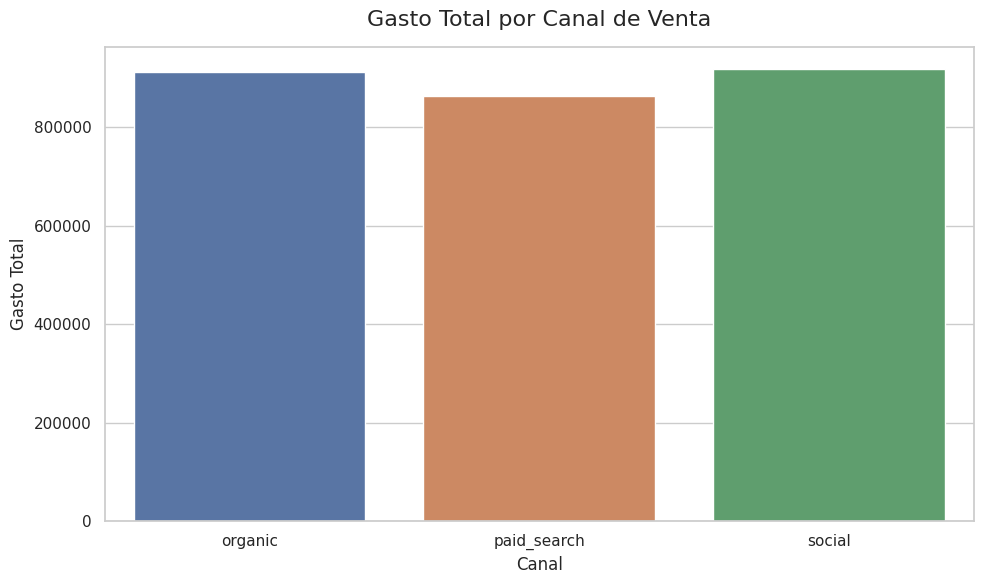

In [60]:

# Configurar el estilo básico de seaborn
sns.set_theme(style="whitegrid")

# Crear el gráfico de barras
plt.figure(figsize=(10, 6))
sns.barplot(x=gasto_por_canal.index, y=gasto_por_canal.values)

# títulos y etiquetas
plt.title("Gasto Total por Canal de Venta", fontsize=16, pad=15)
plt.xlabel("Canal", fontsize=12)
plt.ylabel("Gasto Total", fontsize=12)

# Mostrar el gráfico
plt.tight_layout()
plt.show()


### 💡 Interpretación del negocio
La inversión está distribuida de manera bastante equilibrada entre los tres canales. Sin embargo, Social y Organic concentran los mayores gastos, mientras que Paid Search registra una inversión ligeramente inferior.

Esto permite identificar que no existe una diferencia significativa en el gasto total entre los canales, por lo que sería conveniente analizar también los ingresos y el profit generado por cada uno para determinar cuál ofrece una mayor rentabilidad.
### 📝 Insight

El gasto total presenta una distribución relativamente equilibrada entre los canales de venta. Social y Organic registran los mayores niveles de inversión, mientras que Paid Search presenta el menor gasto. Es importante complementar este análisis con los ingresos y la rentabilidad por canal para identificar cuáles generan un mejor retorno sobre la inversión.

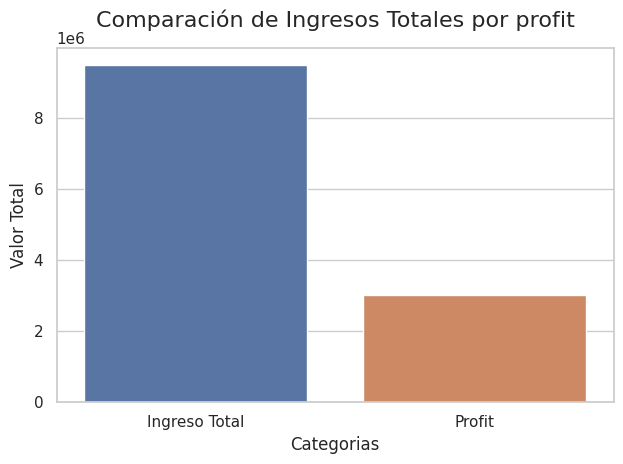

In [61]:

# Lista de categorías (las etiquetas que se verán en el eje X)
categorias = ["Ingreso Total", "Profit"]

# Lista de valores (los números que determinarán la altura de las barras)
valores = [ingreso_total, profit]

# crear el gráfico
sns.barplot(x=categorias, y=valores)

# títulos y etiquetas
plt.title("Comparación de Ingresos Totales por profit", fontsize=16, pad=15)
plt.xlabel("Categorias", fontsize=12)
plt.ylabel("Valor Total", fontsize=12)

# Mostrar el gráfico
plt.tight_layout()
plt.show()


### 💡 Interpretación del negocio

Aunque el negocio genera ingresos cercanos a los 9,5 millones, el beneficio obtenido es de aproximadamente 3 millones. Esto representa un margen de profit cercano al 31,6 % sobre los ingresos totales.
Por lo tanto, sería conveniente analizar los costos y gastos para identificar oportunidades de mejorar la rentabilidad sin afectar los ingresos.

### 📝 Insight



El negocio registra ingresos totales aproximados de 9,5 millones, de los cuales 3 millones corresponden al profit. Esto representa un margen de rentabilidad cercano al 31,6 %. Aunque existe una generación positiva de beneficios, es importante evaluar los costos y gastos para identificar oportunidades de optimización y mejorar la rentabilidad.

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [62]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [63]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [64]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT
    nombre_evento,
    COUNT(DISTINCT id_usuario) AS usuarios_unicos
FROM events
GROUP BY nombre_evento
ORDER BY CASE nombre_evento
    WHEN 'first_visit' THEN 1
    WHEN 'select_item' THEN 2
    WHEN 'add_to_cart' THEN 3
    WHEN 'begin_checkout' THEN 4
    WHEN 'add_payment_info' THEN 5
    WHEN 'purchase' THEN 6
    
END;
'''

totals = pd.read_sql(query_totals, con=engine)
totals


,nombre_evento,usuarios_unicos
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


In [65]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH funnel AS (
    SELECT
        nombre_evento,
        COUNT(DISTINCT id_usuario) AS usuarios_unicos
    FROM events
    GROUP BY nombre_evento
),
ordenado AS (
    SELECT
        nombre_evento,
        usuarios_unicos,     
        CASE nombre_evento
            WHEN 'first_visit' THEN 1
            WHEN 'select_item' THEN 2
            WHEN 'add_to_cart' THEN 3
            WHEN 'begin_checkout' THEN 4
            WHEN 'add_payment_info' THEN 5
            WHEN 'purchase' THEN 6
        END AS etapa
    FROM funnel
),
comparacion AS (
    SELECT
        nombre_evento,
        usuarios_unicos,
        etapa,
        LAG(usuarios_unicos) OVER (
            ORDER BY etapa
        ) AS usuarios_anterior
    FROM ordenado
)
SELECT
    nombre_evento,
    usuarios_unicos,
    usuarios_anterior,
    ROUND(
        100.0 * usuarios_unicos
        / NULLIF(usuarios_anterior, 0),
        2
    ) AS tasa_conversion_pct,
    usuarios_anterior - usuarios_unicos
        AS usuarios_perdidos
FROM comparacion
ORDER BY etapa;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,nombre_evento,usuarios_unicos,usuarios_anterior,tasa_conversion_pct,usuarios_perdidos
0,first_visit,7796,NaN,NaN,NaN
1,select_item,7582,7796.0,97.26,214.0
2,add_to_cart,7634,7582.0,100.69,-52.0
3,begin_checkout,7208,7634.0,94.42,426.0
4,add_payment_info,6250,7208.0,86.71,958.0
5,purchase,6240,6250.0,99.84,10.0


### 📝 Insight

Se identifican 52 usuarios únicos adicionales en el evento add_to_cart respecto a select_item. Esto evidencia que no todos los usuarios siguen necesariamente una secuencia lineal dentro del proceso de compra. Algunos pueden agregar productos directamente al carrito sin generar previamente el evento de selección, por lo que es importante revisar el comportamiento de los eventos antes de interpretar las tasas de conversión del funnel.

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [66]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [67]:

# Explorar actividad y fecha de registro
# =====================================
query_user_activity = '''
SELECT
    ua.*,
    u.fecha_registro,
    CEIL(ua.dias_despues_registro / 7.0) AS semana
FROM user_activity AS ua
JOIN users AS u
    ON ua.id_usuario = u.id_usuario;
'''

user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)


,id_usuario,fecha_actividad,dias_despues_registro,activo,fecha_registro,semana
0,user_0,2025-02-05,7,0,2025-01-29,1.0
1,user_0,2025-02-12,14,1,2025-01-29,2.0
2,user_0,2025-02-19,21,1,2025-01-29,3.0


In [68]:

# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH actividad_semanal AS (
    SELECT
        u.id_usuario,
        TO_CHAR(CAST(u.fecha_registro AS DATE), 'YYYY-MM') AS cohorte,
        ua.activo,
        CEIL(ua.dias_despues_registro / 7.0) AS semana
    FROM users AS u
    JOIN user_activity AS ua
        ON u.id_usuario = ua.id_usuario
),
retencion_usuario AS (
    SELECT
        id_usuario,
        cohorte,
        COALESCE(MAX(CASE WHEN semana = 1 THEN activo END), 0) AS retenido_w1,
        COALESCE(MAX(CASE WHEN semana = 2 THEN activo END), 0) AS retenido_w2,
        COALESCE(MAX(CASE WHEN semana = 3 THEN activo END), 0) AS retenido_w3
    FROM actividad_semanal
    GROUP BY id_usuario, cohorte
)
SELECT
    cohorte,
    COUNT(*) AS usuarios_iniciales,

    SUM(retenido_w1) AS retenido_w1,
    SUM(retenido_w2) AS retenido_w2,
    SUM(retenido_w3) AS retenido_w3,

    ROUND(100.0 * SUM(retenido_w1) / COUNT(*), 2) AS semana_1,
    ROUND(100.0 * SUM(retenido_w2) / COUNT(*), 2) AS semana_2,
    ROUND(100.0 * SUM(retenido_w3) / COUNT(*), 2) AS semana_3

FROM retencion_usuario
GROUP BY cohorte
ORDER BY cohorte;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte,usuarios_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01,1627,697.0,668.0,656.0,42.84,41.06,40.32
1,2025-02,1444,611.0,609.0,635.0,42.31,42.17,43.98
2,2025-03,1636,677.0,705.0,690.0,41.38,43.09,42.18
3,2025-04,1606,680.0,697.0,663.0,42.34,43.40,41.28
4,2025-05,1687,695.0,676.0,706.0,41.20,40.07,41.85


---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** la variable "variante" y la variable "conversión" son independientes (no hay relación entre ellas).
   - **H₁ (Hipótesis alternativa):** hay una relación entre "variante" y "conversión" (la tasa de conversión difiere según la variante).
   
**Test estadístico:** chi-cuadrado    
**Nivel de significancia alpha:** 0.05

In [69]:
# Cargar el archivo
df = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

# Revisar las primeras filas
df.head()

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


In [71]:
# cruce de las columnas 'variante' y 'convirtio'
tabla_contingencia = pd.crosstab(df['variante'], df['convirtio'])
tabla_contingencia

convirtio,0,1
variante,,
control,4186,779
tratamiento,4215,820


In [72]:
# Test estadístico chi-cuadrado

from scipy.stats import chi2_contingency
import pandas as pd

# Crear tabla de contingencia
tabla_contingencia = pd.crosstab(
    df['variante'],
    df['convirtio']
)

print("Tabla de contingencia:")
display(tabla_contingencia)

# Aplicar test chi-cuadrado
chi2, p_value, grados_libertad, frecuencias_esperadas = chi2_contingency(
    tabla_contingencia
)

print("Estadístico chi-cuadrado:", chi2)
print("P-value:", p_value)
print("Grados de libertad:", grados_libertad)
print("Frecuencias esperadas:")
print(frecuencias_esperadas)

Tabla de contingencia:


convirtio,0,1
variante,,
control,4186,779
tratamiento,4215,820


Estadístico chi-cuadrado: 0.6177857659309294
P-value: 0.43187130118526496
Grados de libertad: 1
Frecuencias esperadas:
[[4171.0965  793.9035]
 [4229.9035  805.0965]]


### 📝 Insight

El test chi-cuadrado arrojó un p-value de 0.4319, superior al nivel de significancia de 0.05. Por lo tanto, no se rechaza la hipótesis nula y no existe evidencia estadística suficiente para afirmar que el cambio en la interfaz de pago haya generado una diferencia significativa en la tasa de conversión. Aunque la variante de tratamiento presentó una tasa de conversión del 16.29 %, frente al 15.69 % de la variante de control, esta diferencia no es estadísticamente significativa. Se recomienda no concluir que el cambio fue exitoso basándose únicamente en estos resultados.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

In [126]:
# (Pega aquí tu link)
# link de power bi o tableau
# link de one drive / google drive